In [1]:
import pandas as pd
import numpy as np

In [2]:
!ls ./ODIR/

 DSrenew.ipynb					  close_daili.sh
 ODIR-5K					  connect.sh
 ODIR-5K_Testing_Images				 'full_df (1).csv'
 ODIR-5K_Testing_Images.7z			  full_df.csv
'ODIR-5K_Training_Annotations(Updated)_V2.xlsx'   lightning_logs
 ODIR-5K_Training_Dataset			 'multi label.ipynb'
 ODIR-5K_Training_Images.7z			  open_daili.sh
 XYZ_ODIR.csv					  preprocessed_images
 archive.zip


In [3]:
train_df = pd.read_excel('/home/coffee_dou/python/yuchuli/updated_data.xlsx')
train_df.head()

,ID,Patient Age,Patient Sex,Left-Fundus,Right-Fundus,Left-Diagnostic Keywords,Right-Diagnostic Keywords,N,D,G,C,A,H,M,O
0,0,69,Female,0_left.jpg,0_right.jpg,cataract,normal fundus,0,0,0,1,0,0,0,0
1,1,57,Male,1_left.jpg,1_right.jpg,normal fundus,normal fundus,1,0,0,0,0,0,0,0
2,3,66,Male,3_left.jpg,3_right.jpg,normal fundus,branch retinal artery occlusion,0,0,0,0,0,0,0,1
3,4,53,Male,4_left.jpg,4_right.jpg,macular epiretinal membrane,mild nonproliferative retinopathy,0,1,0,0,0,0,0,1
4,5,50,Female,5_left.jpg,5_right.jpg,moderate non proliferative retinopathy,moderate non proliferative retinopathy,0,1,0,0,0,0,0,0


In [4]:
test_df = pd.read_csv('./ODIR/XYZ_ODIR.csv')
test_df.head()

,ID,N,D,G,C,A,H,M,O
0,937,0,0,0,0,0,0,0,0
1,967,0,0,0,0,0,0,0,0
2,988,0,0,0,0,0,0,0,0
3,995,0,0,0,0,0,0,0,0
4,1000,0,0,0,0,0,0,0,0


In [5]:

from pytorch_lightning import seed_everything, LightningModule, Trainer
from pytorch_lightning.callbacks import EarlyStopping,ModelCheckpoint,LearningRateMonitor
import torch.nn.functional as F
from sklearn.utils import class_weight
from torchvision import transforms 
import torchvision.models as models
import torchmetrics
import torch#pytorch
from sklearn.utils import class_weight
import torch.nn as nn
from torch.optim.lr_scheduler import ReduceLROnPlateau,CosineAnnealingWarmRestarts


In [6]:
import numpy as np
import cv2
from albumentations.core.transforms_interface import ImageOnlyTransform
from albumentations import Compose, Resize, CenterCrop, HorizontalFlip, VerticalFlip, ShiftScaleRotate, RandomBrightnessContrast, CLAHE, Normalize, ToTensorV2

class CustomCutout(ImageOnlyTransform):
    def __init__(self, num_holes=1, max_h_size=8, max_w_size=8, fill_value=0, always_apply=False, p=0.5):
        super(CustomCutout, self).__init__(always_apply, p)
        self.num_holes = num_holes
        self.max_h_size = max_h_size
        self.max_w_size = max_w_size
        self.fill_value = fill_value

    def apply(self, image, **params):
        for _ in range(self.num_holes):
            x = np.random.randint(0, image.shape[1])
            y = np.random.randint(0, image.shape[0])
            h = np.random.randint(1, self.max_h_size + 1)
            w = np.random.randint(1, self.max_w_size + 1)
            x1 = np.clip(x - w // 2, 0, image.shape[1])
            y1 = np.clip(y - h // 2, 0, image.shape[0])
            x2 = np.clip(x + w // 2, 0, image.shape[1])
            y2 = np.clip(y + h // 2, 0, image.shape[0])
            image[y1:y2, x1:x2] = self.fill_value
        return image

aug = Compose([
    Resize(256, 256),
    CenterCrop(224, 224),
    HorizontalFlip(p=0.5),
    VerticalFlip(p=0.5),
    ShiftScaleRotate(0.05, 0.05, 5),
    RandomBrightnessContrast(p=0.5),
    CLAHE(),
    CustomCutout(num_holes=1, max_h_size=16, max_w_size=16, fill_value=0, p=0.5),
    Normalize(mean=(0, 0, 0), std=(1, 1, 1)),
    ToTensorV2(p=1.0),
], p=1.0, additional_targets={'image0': 'image'}, is_check_shapes=False)


/root/anaconda3/lib/python3.12/site-packages/albumentations/check_version.py:107: UserWarning: Error fetching version info The read operation timed out
  data = fetch_version_info()
/root/anaconda3/lib/python3.12/site-packages/albumentations/core/validation.py:87: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [7]:
train_path='/home/coffee_dou/python/yuchuli/123/123/'

In [8]:
class DataReader(torch.utils.data.Dataset):
    def __init__(self, df, path, transform=None):
        super(DataReader, self).__init__()
        self.df = df
        self.path = path
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        # 使用 .iloc 提取路径
        image_path = self.df.iloc[index, 0]
        
        # 使用 .iloc 提取标签，并确保转换为数值类型
        image_label = self.df.iloc[index, -8:].astype(float).values

        # 拼接完整的图像路径
        left_path = os.path.join(self.path, str(image_path) + '_left.jpg')
        right_path = os.path.join(self.path, str(image_path) + '_right.jpg')

        # 检查文件是否存在
        if not os.path.exists(left_path) or not os.path.exists(right_path):
            raise FileNotFoundError(f"Image file not found: {left_path} or {right_path}")

        # 读取图像
        left = cv2.imread(left_path)
        right = cv2.imread(right_path)

        # 检查图像是否成功读取
        if left is None or right is None:
            raise ValueError(f"Failed to read image: {left_path} or {right_path}")

        # 将图像从 BGR 转换为 RGB
        left = cv2.cvtColor(left, cv2.COLOR_BGR2RGB)
        right = cv2.cvtColor(right, cv2.COLOR_BGR2RGB)

        # 应用数据增强（如果有）
        if self.transform:
            image = self.transform(image=left, image0=right)
            left = image['image']
            right = image['image0']

        # 将标签转换为 PyTorch 张量
        return left, right, torch.tensor(image_label, dtype=torch.float32)

In [9]:
# train = DataReader(train_df, train_path, aug)
# train_loader = DataLoader(train, shuffle=True, num_workers=0, batch_size=16)

# # 获取第一个批次的数据
# left, right, label = next(iter(train_loader))
# print("Left shape:", left.shape)
# print("Right shape:", right.shape)
# print("Label shape:", label.shape)


In [10]:
from torch.utils.data import DataLoader
import os
train=DataReader(train_df,train_path,aug)
train_loader = DataLoader(train,shuffle=True,num_workers=0,batch_size=16)
left,right,label=next(iter(train_loader))
print(left.shape,right.shape,label.shape)

torch.Size([16, 3, 224, 224]) torch.Size([16, 3, 224, 224]) torch.Size([16, 8])


In [11]:
# mean,std=[],[]
# for x,_,_ in train_loader:
#     mean.append(torch.mean(x/255, dim=(0, 2,3)))
#     std.append(torch.std(x/255, dim=(0, 2,3)))
# print(np.mean(np.stack(mean),axis=0))
# print(np.mean(np.stack(std),axis=0))

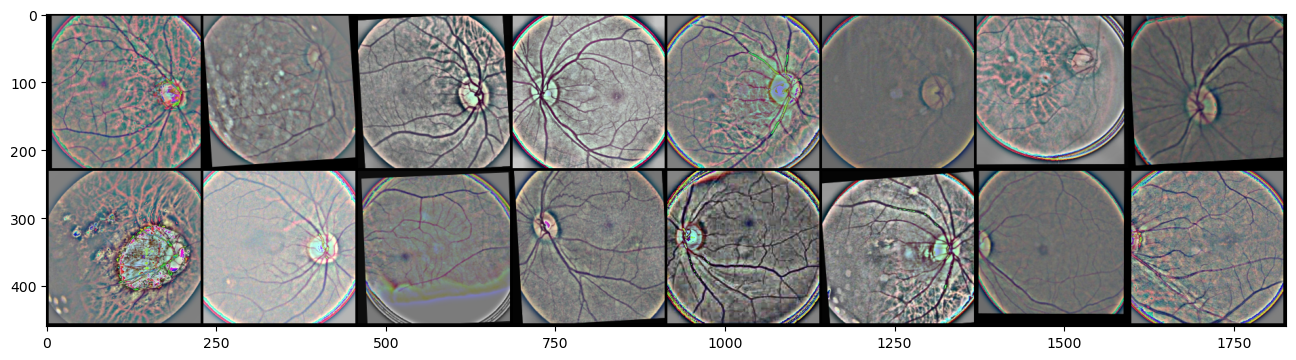

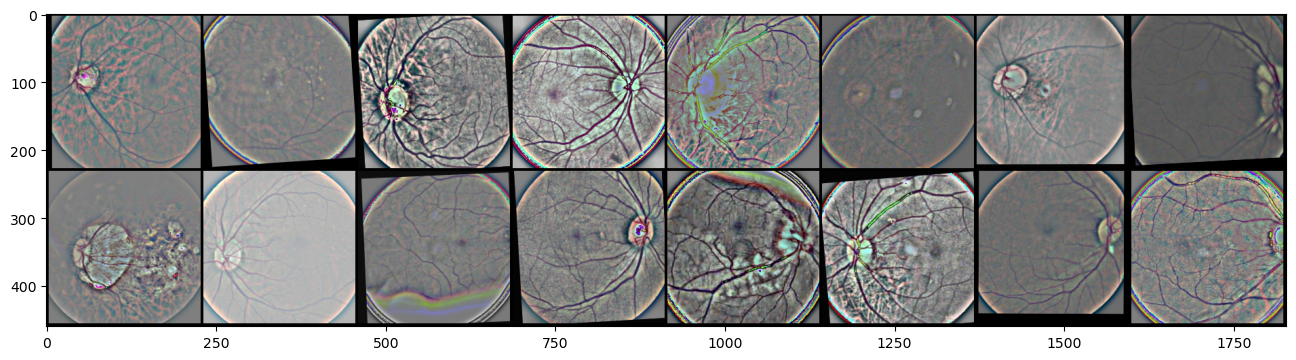

In [12]:
from torch.utils.data.dataloader import DataLoader
import torchvision
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
from torch.utils.data import DataLoader
import timm
import pytorch_lightning as pl
from pytorch_lightning import LightningModule
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score, cohen_kappa_score
import pandas as pd
import os
import cv2
from albumentations import Compose, Resize, CenterCrop, HorizontalFlip, VerticalFlip, ShiftScaleRotate, RandomBrightnessContrast, CLAHE, Normalize, ToTensorV2
plt.figure(figsize=(16,16))
grid_img=torchvision.utils.make_grid(left,8,4)
plt.imshow(grid_img.permute(1, 2, 0))
plt.figure(figsize=(16,16))
grid_img=torchvision.utils.make_grid(right,8,4)
plt.imshow(grid_img.permute(1, 2, 0))

In [13]:
# #test
# model = densenet121()
# x=torch.randn(1,3,224,224)
# l=model(x)
# r=model(x)
# x=torch.cat([l,r],dim=1)
# print(x.shape)
# l=nn.Linear(2000,1000)
# x=l(x)
# x.shape

In [14]:
from sklearn.model_selection import train_test_split
from sklearn import metrics
from torchvision.models import densenet121,resnet50
import pytorch_lightning as pl
import time
import timm
train_df,val_df=train_test_split(train_df,test_size=0.25,random_state=21)

In [15]:
class OurModel(pl.LightningModule):
    def __init__(self):
        super(OurModel, self).__init__()
        # Architecture
        self.model = timm.create_model('resnet18d', pretrained=True)

        self.fc1 = nn.Linear(2000, 1000)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(1000, 8)

        # Parameters
        self.lr = 1e-3
        self.batch_size = 96
        self.numworker = 8
        self.criterion = nn.BCEWithLogitsLoss(reduction='none')  # Internal sigmoid

        # For storing outputs
        self.validation_step_outputs = []
        self.test_losses = []
        self.test_labels = []
        self.test_preds = []

        # For storing dynamic thresholds
        self.dynamic_thresholds = None

    def forward(self, xl, xr):
        l = self.model(xl)
        r = self.model(xr)
        x = torch.cat((l, r), 1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

    def focal(self, BCE, alpha=0.5, gamma=2):
        BCE_EXP = torch.exp(-BCE)
        focal_loss = alpha * (1 - BCE_EXP) ** gamma * BCE
        return focal_loss.mean()

    def configure_optimizers(self):
        opt = torch.optim.Adam(self.parameters(), lr=self.lr, weight_decay=1e-4)
        scheduler = CosineAnnealingWarmRestarts(opt, T_0=5, T_mult=1, eta_min=1e-5, last_epoch=-1)
        return {'optimizer': opt, 'lr_scheduler': scheduler, 'monitor': 'val_loss'}

    def train_dataloader(self):
        return DataLoader(DataReader(train_df, train_path, aug), batch_size=self.batch_size,
                          num_workers=self.numworker, shuffle=True)

    def training_step(self, batch, batch_idx):
        left, right, label = batch
        out = self(left, right)
        loss = self.focal(self.criterion(out, label))
        self.log('train_loss', loss, on_epoch=True, prog_bar=True)
        return loss

    def val_dataloader(self):
        return DataLoader(DataReader(val_df, train_path, aug), batch_size=self.batch_size,
                          num_workers=self.numworker, shuffle=False)

    def validation_step(self, batch, batch_idx):
        left, right, label = batch
        out = self(left, right)
        loss = self.focal(self.criterion(out, label))
        self.log('val_loss', loss, on_epoch=True, prog_bar=True)
        # Save outputs for later use in on_validation_epoch_end
        self.validation_step_outputs.append({'val_loss': loss, 'preds': torch.sigmoid(out).detach(), 'labels': label.detach()})
        return {'val_loss': loss}

    def on_validation_epoch_end(self):
        # Calculate dynamic thresholds based on validation data
        all_preds = torch.cat([output['preds'] for output in self.validation_step_outputs]).cpu().numpy()
        all_labels = torch.cat([output['labels'] for output in self.validation_step_outputs]).cpu().numpy()
        self.dynamic_thresholds = self.calculate_dynamic_thresholds(all_labels, all_preds)
        # Clear the outputs to free memory
        self.validation_step_outputs.clear()

    def calculate_dynamic_thresholds(self, labels, preds):
        """
        Calculate dynamic thresholds based on validation data
        """
        thresholds = []
        for i in range(8):  # Assuming 8 classes
            best_threshold = 0.5
            best_f1 = 0
            for threshold in np.arange(0.1, 0.9, 0.02):  # Step size changed to 0.02
                binary_preds = (preds[:, i] > threshold).astype(int)
                f1 = f1_score(labels[:, i], binary_preds, average='binary')
                if f1 > best_f1:
                    best_f1 = f1
                    best_threshold = threshold
            # Only print the best threshold and F1 score for each class
            print(f"Class {i}: Best threshold {best_threshold:.2f} with F1 score: {best_f1:.4f}")
            thresholds.append(best_threshold)
        return np.array(thresholds)

    def on_save_checkpoint(self, checkpoint):
        # Save dynamic_thresholds to the checkpoint
        checkpoint['dynamic_thresholds'] = self.dynamic_thresholds

    def on_load_checkpoint(self, checkpoint):
        # Load dynamic_thresholds from the checkpoint
        self.dynamic_thresholds = checkpoint.get('dynamic_thresholds', None)

    def test_dataloader(self):
        return DataLoader(DataReader(val_df, train_path, aug), batch_size=self.batch_size,
                          num_workers=self.numworker, shuffle=False)

    def test_step(self, batch, batch_idx):
        left, right, label = batch
        out = self(left, right)
        loss = self.focal(self.criterion(out, label))
        self.test_losses.append(loss)
        self.test_labels.append(label.detach())
        self.test_preds.append(torch.sigmoid(out).detach())
        return {'loss': loss, 'label': label.detach(), 'pred': torch.sigmoid(out).detach()}

    def on_test_epoch_end(self):
        avg_loss = torch.stack(self.test_losses).mean()
        labels = torch.cat(self.test_labels).cpu().numpy()
        preds = torch.cat(self.test_preds).cpu().numpy()

        # Apply dynamic thresholds
        binary_preds = np.where(preds > self.dynamic_thresholds, 1, 0)

        kappa, f1, auc, final_score, acc = self.ODIR_Metrics(labels, binary_preds)

        self.log('kappa', np.round(kappa, 3))
        self.log('f1', np.round(f1, 3))
        self.log('auc', np.round(auc, 3))
        self.log('final', np.round(final_score, 3))
        self.log('acc', np.round(acc, 3))

        # Clear the lists for the next epoch
        self.test_losses.clear()
        self.test_labels.clear()
        self.test_preds.clear()

    def ODIR_Metrics(self, gt_data, pr_data):
        th = 0.5
        gt_data = gt_data.flatten()
        pr_data = pr_data.flatten()
        kappa = metrics.cohen_kappa_score(gt_data, pr_data)
        f1 = metrics.f1_score(gt_data, pr_data, average='micro')
        auc = metrics.roc_auc_score(gt_data, pr_data)
        acc = metrics.accuracy_score(gt_data, pr_data)
        final_score = (kappa + f1 + auc) / 3.0
        return kappa, f1, auc, final_score, acc

In [16]:
from pytorch_lightning.callbacks import LearningRateMonitor, EarlyStopping, ModelCheckpoint

# 定义回调函数
lr_monitor = LearningRateMonitor(logging_interval='epoch')
early_stop_callback = EarlyStopping(monitor='val_loss', patience=10, verbose=True, mode='min')
checkpoint_callback = ModelCheckpoint(monitor='val_loss', dirpath='./checkpoints', filename='savefile')

# 初始化模型
model = OurModel()

# 初始化训练器
trainer = Trainer(
    max_epochs=25,
    accelerator="gpu",  # 指定使用 GPU
    devices=-1,  # 使用所有可用的 GPU
    precision=16,  # 使用混合精度训练
    callbacks=[checkpoint_callback, early_stop_callback, lr_monitor]
)



/root/anaconda3/lib/python3.12/site-packages/lightning_fabric/connector.py:571: `precision=16` is supported for historical reasons but its usage is discouraged. Please set your precision to 16-mixed instead!
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


In [17]:
%%time
trainer.fit(model)
print("finsh")

You are using a CUDA device ('NVIDIA GeForce RTX 4060 Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
2025-04-03 20:25:31.239284: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-03 20:25:31.247921: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1743683131.258019    2382 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory 

Sanity Checking: |                                                                                | 0/? [00:00…

Class 0: Best threshold 0.36 with F1 score: 0.6058
Class 1: Best threshold 0.38 with F1 score: 0.1722
Class 2: Best threshold 0.56 with F1 score: 0.1429
Class 3: Best threshold 0.10 with F1 score: 0.1268
Class 4: Best threshold 0.48 with F1 score: 0.1348
Class 5: Best threshold 0.58 with F1 score: 0.0684
Class 6: Best threshold 0.44 with F1 score: 0.1554
Class 7: Best threshold 0.42 with F1 score: 0.4672


/root/anaconda3/lib/python3.12/site-packages/pytorch_lightning/loops/fit_loop.py:310: The number of training batches (21) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Training: |                                                                                       | 0/? [00:00…

...

Validation: |                                                                                     | 0/? [00:00…

Class 0: Best threshold 0.36 with F1 score: 0.7405
Class 1: Best threshold 0.32 with F1 score: 0.3357
Class 2: Best threshold 0.54 with F1 score: 0.6038
Class 3: Best threshold 0.48 with F1 score: 0.8723
Class 4: Best threshold 0.36 with F1 score: 0.6512
Class 5: Best threshold 0.24 with F1 score: 0.8000
Class 6: Best threshold 0.40 with F1 score: 0.9412
Class 7: Best threshold 0.32 with F1 score: 0.4850


Validation: |                                                                                     | 0/? [00:00…

Monitored metric val_loss did not improve in the last 10 records. Best score: 0.029. Signaling Trainer to stop.


Class 0: Best threshold 0.32 with F1 score: 0.7535
Class 1: Best threshold 0.36 with F1 score: 0.3623
Class 2: Best threshold 0.50 with F1 score: 0.6250
Class 3: Best threshold 0.48 with F1 score: 0.8791
Class 4: Best threshold 0.38 with F1 score: 0.7188
Class 5: Best threshold 0.72 with F1 score: 0.7755
Class 6: Best threshold 0.48 with F1 score: 0.9767
Class 7: Best threshold 0.42 with F1 score: 0.5027
finsh
CPU times: user 2min 8s, sys: 11.4 s, total: 2min 20s
Wall time: 3min 30s


In [18]:
trainer.test()

/root/anaconda3/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:149: `.test(ckpt_path=None)` was called without a model. The best model of the previous `fit` call will be used. You can pass `.test(ckpt_path='best')` to use the best model or `.test(ckpt_path='last')` to use the last model. If you pass a value, this warning will be silenced.
Restoring states from the checkpoint path at /home/coffee_dou/python/ODIR2019-master/more/checkpoints/savefile-v39.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loaded model weights from the checkpoint at /home/coffee_dou/python/ODIR2019-master/more/checkpoints/savefile-v39.ckpt


Testing: |                                                                                        | 0/? [00:00…

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│            acc            │    0.8859999775886536     │
│            auc            │    0.8259999752044678     │
│            f1             │    0.8859999775886536     │
│           final           │    0.7620000243186951     │
│           kappa           │    0.5730000138282776     │
└───────────────────────────┴───────────────────────────┘

[{'kappa': 0.5730000138282776,
  'f1': 0.8859999775886536,
  'auc': 0.8259999752044678,
  'final': 0.7620000243186951,
  'acc': 0.8859999775886536}]

In [19]:
# submission

In [20]:
submission_df=pd.read_excel('/home/coffee_dou/python/yuchuli/val.xlsx')
submission_df.head()

,ID,N,D,G,C,A,H,M,O
0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0
2,3,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0
4,5,0,0,0,0,0,0,0,0


In [21]:
test_path='/home/coffee_dou/python/yuchuli/123/123/'

In [22]:
loader=DataLoader(DataReader(submission_df,test_path,aug), batch_size = model.batch_size,num_workers=model.numworker,shuffle=False)
batch=next(iter(loader))
batch[0].shape,batch[1].shape


(torch.Size([96, 3, 224, 224]), torch.Size([96, 3, 224, 224]))

In [23]:
model=model.cuda()
preds=[]
with torch.no_grad():
    model.eval()
    for batch in loader:
        preds.append(model(batch[0].cuda(),batch[1].cuda()))


In [24]:
preds=torch.cat(preds)
preds.shape


torch.Size([2601, 8])

In [25]:
preds=preds.detach().cpu().numpy()


In [26]:
preds=np.where(preds>0.5,1,0)#convert probabilities to target


In [27]:
for i,j in enumerate(submission_df.columns[1::]):
    submission_df[j]=preds[:,i]


In [28]:
submission_df.head()


,ID,N,D,G,C,A,H,M,O
0,0,0,0,0,1,0,0,0,0
1,1,1,0,0,0,0,0,0,0
2,3,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,1
4,5,0,0,0,0,0,0,0,0


In [30]:
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, classification_report
)
import torch

class ModelEvaluator:
    def __init__(self, model, val_loader):
        self.model = model.cuda()
        self.val_loader = val_loader
    
    def evaluate(self):
        all_labels = []
        all_preds = []
        with torch.no_grad():
            for batch in self.val_loader:
                left, right, labels = [x.cuda() for x in batch]
                outputs = self.model(left, right)
                all_labels.append(labels.cpu())
                all_preds.append(torch.sigmoid(outputs).cpu())
        
        labels = torch.cat(all_labels).numpy()
        preds = torch.cat(all_preds).numpy()
        binary_preds = (preds > 0.5).astype(int)
        
        # 逐类计算指标
        class_names = ['Class_0', 'Class_1', 'Class_2', 'Class_3',
                      'Class_4', 'Class_5', 'Class_6', 'Class_7']
        
        print("\n=== 逐类性能 ===")
        metrics_dict = {}
        for i in range(8):
            acc = accuracy_score(labels[:, i], binary_preds[:, i])
            pre = precision_score(labels[:, i], binary_preds[:, i], zero_division=0)
            rec = recall_score(labels[:, i], binary_preds[:, i], zero_division=0)
            f1 = f1_score(labels[:, i], binary_preds[:, i], zero_division=0)
            auc = roc_auc_score(labels[:, i], preds[:, i])
            
            metrics_dict[class_names[i]] = {
                'Accuracy': acc,
                'Precision': pre,
                'Recall': rec,
                'F1': f1,
                'AUC': auc
            }
            print(f"\n{class_names[i]}:")
            print(f"Accuracy: {acc:.4f}")
            print(f"Precision: {pre:.4f}")
            print(f"Recall: {rec:.4f}")
            print(f"F1 Score: {f1:.4f}")
            print(f"AUC: {auc:.4f}")
        
        # 总体性能
        print("\n=== 总体性能 ===")
        print(f"Micro F1: {f1_score(labels, binary_preds, average='micro'):.4f}")
        print(f"Macro AUC: {roc_auc_score(labels, preds, average='macro'):.4f}")
        print(f"Cohen Kappa: {cohen_kappa_score(labels, binary_preds):.4f}")
        print("\n分类报告:\n", classification_report(labels, binary_preds, target_names=class_names))
        
        return metrics_dict

# 使用示例
if __name__ == '__main__':
    # 加载模型和数据
    model = OurModel.load_from_checkpoint('/home/coffee_dou/python/ODIR2019-master/more/checkpoints/savefile-v39.ckpt')
    val_loader = DataLoader(DataReader(val_df, train_path, aug), batch_size=32)
    
    # 执行评估
    evaluator = ModelEvaluator(model, val_loader)
    metrics = evaluator.evaluate()


=== 逐类性能 ===

Class_0:
Accuracy: 0.7634
Precision: 0.7152
Recall: 0.7700
F1 Score: 0.7416
AUC: 0.8372

Class_1:
Accuracy: 0.8817
Precision: 0.3333
Recall: 0.0845
F1 Score: 0.1348
AUC: 0.6839

Class_2:
Accuracy: 0.9616
Precision: 0.5385
Recall: 0.5185
F1 Score: 0.5283
AUC: 0.9620

Class_3:
Accuracy: 0.9754
Precision: 0.8222
Recall: 0.8222
F1 Score: 0.8222
AUC: 0.9870

Class_4:
Accuracy: 0.9677
Precision: 0.8000
Recall: 0.5556
F1 Score: 0.6557
AUC: 0.9512

Class_5:
Accuracy: 0.9816
Precision: 0.9444
Recall: 0.6071
F1 Score: 0.7391
AUC: 0.9835

Class_6:
Accuracy: 0.9892
Precision: 0.9737
Recall: 0.8605
F1 Score: 0.9136
AUC: 0.9989

Class_7:
Accuracy: 0.7542
Precision: 0.5426
Recall: 0.4094
F1 Score: 0.4667
AUC: 0.7321

=== 总体性能 ===
Micro F1: 0.6413
Macro AUC: 0.8920


ValueError: multilabel-indicator is not supported

In [34]:
import pandas as pd
import torch
import numpy as np
from torch.utils.data import DataLoader

class InferenceModel:
    def __init__(self, ckpt_path='/home/coffee_dou/python/ODIR2019-master/more/checkpoints/savefile-v39.ckpt'):
        self.model = OurModel.load_from_checkpoint(ckpt_path)
        self.model.eval()
        self.model.cuda()
        
        if self.model.dynamic_thresholds is None:
            raise ValueError("Dynamic thresholds are not found in the checkpoint. Please ensure they are saved during training.")
        
        self.dynamic_thresholds = self.model.dynamic_thresholds  # 加载动态阈值
    
    def predict(self, test_csv='/home/coffee_dou/python/ODIR2019-master/more/imgyuchuli/img/验证集/validation_参赛队伍编号.xlsx', test_path='/home/coffee_dou/python/ODIR2019-master/more/imgyuchuli/img/验证集/增强/'):
        # 读取测试数据
        test_df = pd.read_excel(test_csv)

        # 只保留 ID ≠ 0 的数据进行预测
        test_df_filtered = test_df[test_df['ID'] != 0].reset_index(drop=True)

        test_dataset = DataReader(test_df_filtered, test_path, aug)
        test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
        
        # 进行推理
        preds = []
        with torch.no_grad():
            for batch in test_loader:
                left, right, _ = [x.cuda() for x in batch]
                outputs = self.model(left, right)
                preds.append(torch.sigmoid(outputs).cpu())

        # 处理预测结果
        preds = torch.cat(preds).numpy()
        binary_preds = np.where(preds > self.dynamic_thresholds, 1, 0)

        # 复制原数据，保证格式一致
        submission = test_df.copy()

        # 仅更新 ID ≠ 0 的 N~O 列
        submission.loc[submission['ID'] != 0, ['N', 'D', 'G', 'C', 'A', 'H', 'M', 'O']] = binary_preds

        # 保存 CSV
        submission.to_csv('predicted_results.csv', index=False)
        return submission

if __name__ == '__main__':
    infer = InferenceModel()
    results = infer.predict()
    print("推理完成，结果已保存到 predicted_results.csv")


推理完成，结果已保存到 predicted_results.csv
